In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

from analytics.db import query
from analytics.paths import FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
query("""
      --w010
      SELECT COUNT(*) AS orders_with_more_than_3_items
FROM (
    SELECT order_id
    FROM clean.order_items
    GROUP BY order_id
    HAVING COUNT(*) > 3
) AS orders_over_3;
      
      """)

,orders_with_more_than_3_items
0,965


In [3]:

freight = query("""
    SELECT c.customer_state AS state, AVG(i.freight_value) AS freight
    FROM clean.order_items AS i
    JOIN clean.orders AS o ON o.order_id = i.order_id
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
    GROUP BY c.customer_state
    ORDER BY freight DESC
    LIMIT 5
""")

freight


,state,freight
0,RR,42.984423
1,PB,42.723804
2,RO,41.069712
3,AC,40.073370
4,PI,39.147970


This query retrieves the five states with the highest average freight cost per item. It joins the order items, orders, and customers tables to connect each item with the customer's state. Then, it groups the results by state, calculates the average freight cost, sorts the results in descending order, and returns only the top five states.

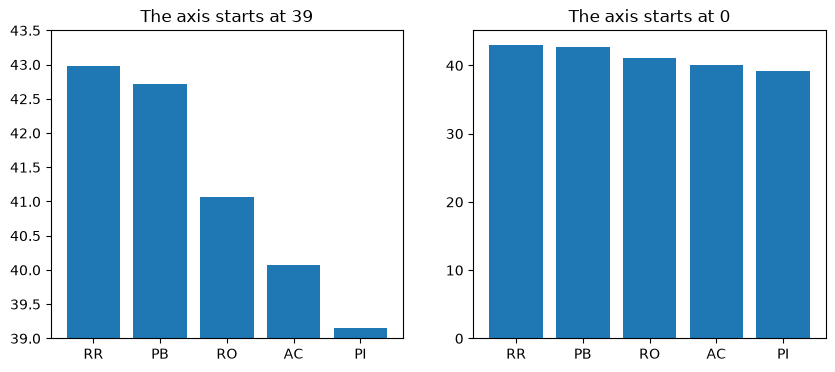

In [4]:

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))

left.bar(freight["state"], freight["freight"])
left.set_ylim(39, 43.5)
left.set_title("The axis starts at 39")

right.bar(freight["state"], freight["freight"])
right.set_title("The axis starts at 0")

plt.show()


This code creates two bar charts using the same freight data. The left chart starts its Y-axis at 39, while the right chart starts at 0. This comparison demonstrates how changing the Y-axis limits can make small differences between values look much larger than they really are.

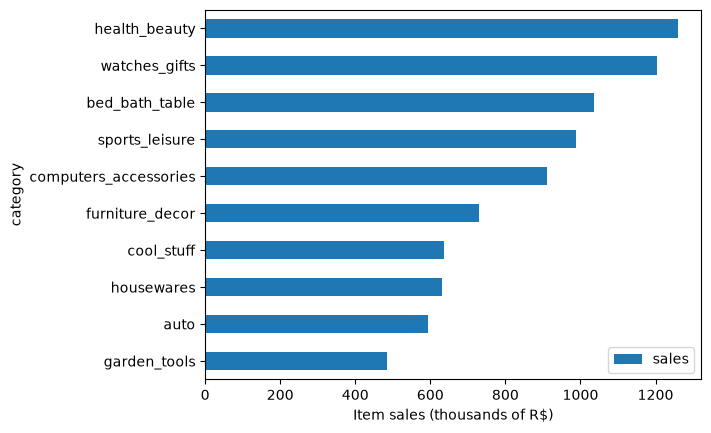

In [5]:

category_sales = query("""
    SELECT p.category, SUM(i.price) / 1000 AS sales
    FROM clean.order_items AS i
    JOIN clean.products AS p ON p.product_id = i.product_id
    GROUP BY p.category
    ORDER BY sales DESC
    LIMIT 10
""")

ax = category_sales.sort_values("sales").plot(kind="barh", x="category", y="sales", legend=True)
ax.set_xlabel("Item sales (thousands of R$)")
plt.show()


This query calculates the total sales for each product category and retrieves the top 10 categories with the highest sales. The results are then displayed using a horizontal bar chart. The categories are sorted in ascending order so that the highest-selling category appears at the top. The chart uses thousands of Brazilian Reais to make the values easier to read.

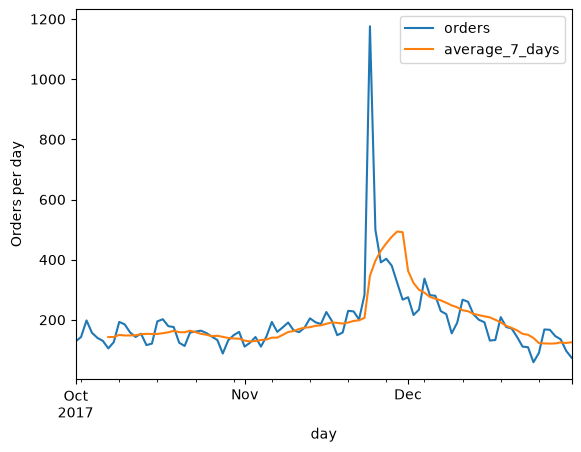

In [6]:

daily = query("""
    SELECT date_trunc('day', order_purchase_timestamp) AS day, COUNT(*) AS orders
    FROM clean.orders
    WHERE order_purchase_timestamp >= '2017-10-01'
      AND order_purchase_timestamp < '2018-01-01'
    GROUP BY 1
    ORDER BY 1
""").set_index("day")

daily["average_7_days"] = daily["orders"].rolling(7).mean()

ax = daily.plot(y=["orders", "average_7_days"])
ax.set_ylabel("Orders per day")
plt.show()


This query retrieves the daily number of orders from October to December 2017. The data is grouped by day and sorted chronologically. The 7-day rolling average is calculated to make the trend easier to understand by reducing daily fluctuations. Finally, a line chart displays both the actual daily orders and the 7-day average for comparison.

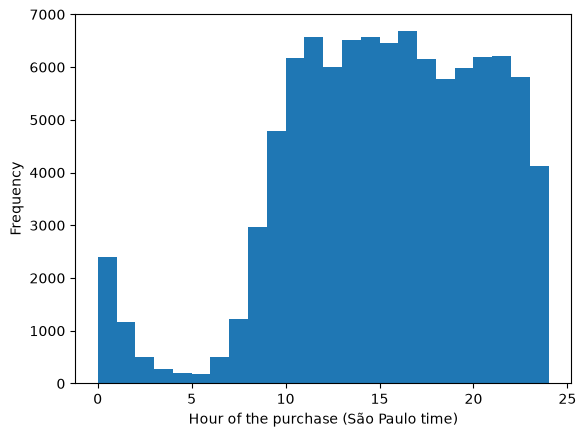

In [7]:

purchases = query("SELECT order_purchase_timestamp FROM clean.orders")

ax = purchases["order_purchase_timestamp"].dt.hour.plot(kind="hist", bins=24, range=(0, 24))
ax.set_xlabel("Hour of the purchase (São Paulo time)")
plt.show()


This query retrieves the purchase timestamps from the orders table. The .dt.hour accessor extracts the hour from each purchase timestamp. A histogram with 24 bins is used to show the distribution of purchases throughout the day, with each bin representing one hour. The chart helps identify the busiest and quietest hours.

In [8]:

weights = query("""
    SELECT p.product_weight_g, i.freight_value
    FROM clean.order_items AS i
    JOIN clean.products AS p ON p.product_id = i.product_id
""")


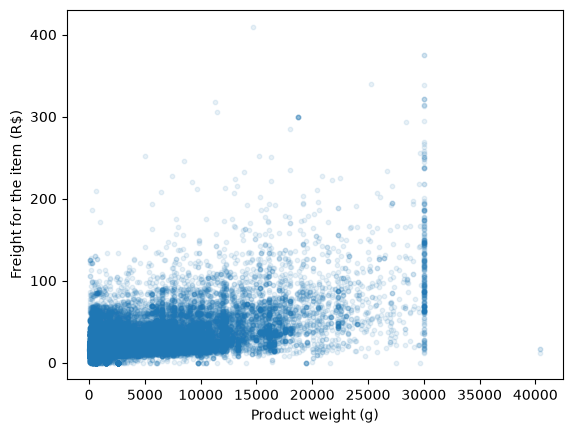

In [9]:

ax = weights.plot(kind="scatter", x="product_weight_g", y="freight_value", s=10, alpha=0.1)

ax.set_xlabel("Product weight (g)")
ax.set_ylabel("Freight for the item (R$)")

plt.show()


This code creates a scatter plot to explore the relationship between product weight and freight cost. Each dot represents one order item. Product weight is displayed on the X-axis, while freight cost is displayed on the Y-axis. The small marker size and transparency help make overlapping points easier to understand. The chart shows that heavier products generally have higher freight costs, although this is not always the case.

In [10]:
 
payments = query("""
    SELECT payment_type, SUM(payment_value) AS money
    FROM clean.order_payments
    GROUP BY payment_type
    ORDER BY money DESC
""").set_index("payment_type")

payments["share"] = 100 * payments["money"] / payments["money"].sum()



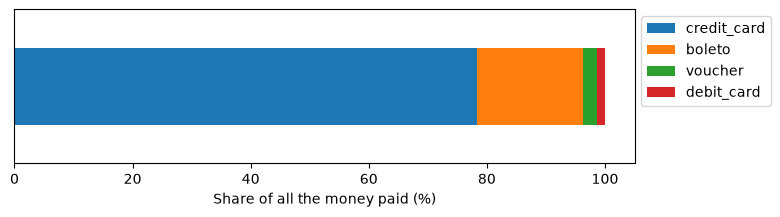

In [11]:

ax = payments[["share"]].T.plot(kind="barh", stacked=True, figsize=(8, 2))

ax.set_xlabel("Share of all the money paid (%)")
ax.set_yticks([])
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.show()


This query calculates the total payment amount for each payment type. The share column converts each payment type's total amount into a percentage of all money paid. A horizontal stacked bar chart is then used to compare the percentage of each payment method. Credit cards represent the largest share of the total payment amount at 78.3%.


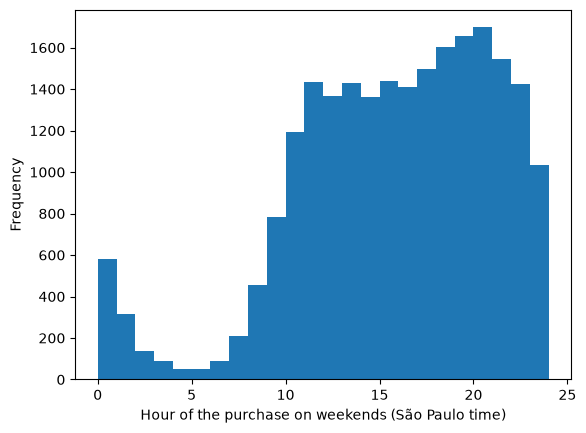

In [12]:
#1.a

weekend_mask = purchases["order_purchase_timestamp"].dt.dayofweek.isin([5, 6])

weekend = purchases[weekend_mask]

ax = weekend["order_purchase_timestamp"].dt.hour.plot(
    kind="hist",
    bins=24,
    range=(0, 24)
)

ax.set_xlabel("Hour of the purchase on weekends (São Paulo time)")
plt.show()


This code filters the purchase records to include Saturdays and Sundays only, using the dayofweek accessor. It then extracts the purchase hour and creates a histogram with 24 bins to show the distribution of weekend purchases throughout the day.

In [13]:
#1.b
product_weights = query("""
    SELECT product_id, product_weight_g
    FROM clean.products
""")

product_weights


,product_id,product_weight_g
0,1e9e8ef04dbcff4541ed26657ea517e5,225.0
1,3aa071139cb16b67ca9e5dea641aaa2f,1000.0
2,96bd76ec8810374ed1b65e291975717f,154.0
3,cef67bcfe19066a932b7673e239eb23d,371.0
4,9dc1a7de274444849c219cff195d0b71,625.0
...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,12300.0
32947,bf4538d88321d0fd4412a93c974510e6,1700.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,1400.0
32949,83808703fc0706a22e264b9d75f04a2e,700.0


This query retrieves each product's ID and weight from the products table. The resulting DataFrame will be used to count products with a weight of exactly 30,000 grams and products weighing more than 30,000 grams.

In [14]:
#1.b

exactly_30000 = (product_weights["product_weight_g"] == 30000).sum()

over_30000 = (product_weights["product_weight_g"] > 30000).sum()

print("Products weighing exactly 30,000 g:", exactly_30000)
print("Products weighing more than 30,000 g:", over_30000)


Products weighing exactly 30,000 g: 143
Products weighing more than 30,000 g: 1


This code counts products weighing exactly 30,000 grams and products weighing more than 30,000 grams. It uses comparison conditions to create True and False values, then sums them because pandas treats True as 1 and False as 0. The print() function displays both counts.

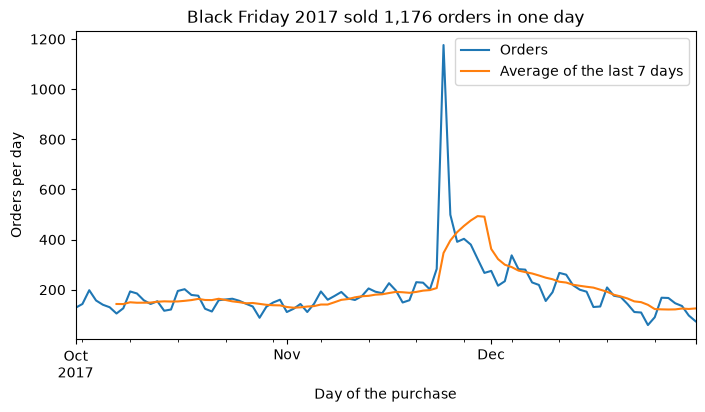

In [15]:

ax = daily.plot(y=["orders", "average_7_days"], figsize=(8, 4))

ax.set_title("Black Friday 2017 sold 1,176 orders in one day")
ax.set_xlabel("Day of the purchase")
ax.set_ylabel("Orders per day")

ax.legend(["Orders", "Average of the last 7 days"])

ax.figure.savefig(FIGURES / "day-10-black-friday.png", bbox_inches="tight")

plt.show()


This code recreates the daily orders line chart with a clear message title highlighting the Black Friday result. It adds descriptive labels to both axes and meaningful names to the two lines. Finally, savefig() exports the chart as a PNG image into the reports/figures directory, with unnecessary empty borders removed.

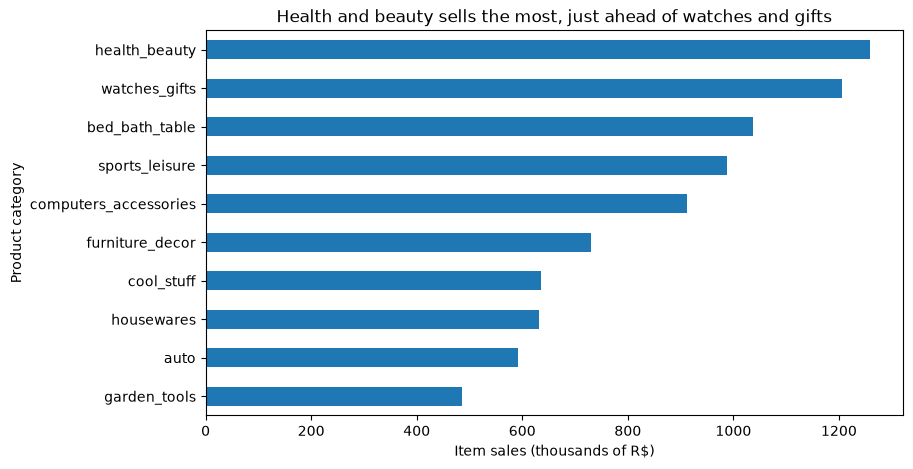

In [16]:

ax = category_sales.sort_values("sales").plot(
    kind="barh",
    x="category",
    y="sales",
    legend=False,
    figsize=(9, 5)
)

ax.set_title("Health and beauty sells the most, just ahead of watches and gifts")
ax.set_xlabel("Item sales (thousands of R$)")
ax.set_ylabel("Product category")

ax.figure.savefig(FIGURES / "day-10-categories.png", bbox_inches="tight")

plt.show()


This code recreates the top 10 product categories sales chart with a message title highlighting the highest-selling category. It adds clear labels to both axes and saves the chart as a PNG image in the reports/figures directory.

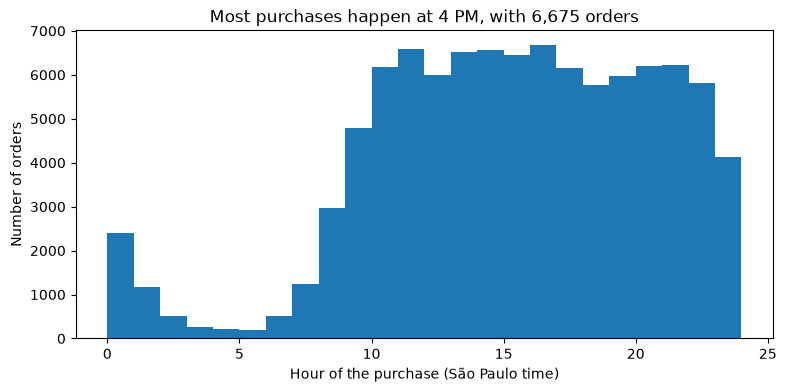

In [17]:

ax = purchases["order_purchase_timestamp"].dt.hour.plot(
    kind="hist",
    bins=24,
    range=(0, 24),
    figsize=(9, 4)
)

ax.set_title("Most purchases happen at 4 PM, with 6,675 orders")
ax.set_xlabel("Hour of the purchase (São Paulo time)")
ax.set_ylabel("Number of orders")

ax.figure.savefig(FIGURES / "day-10-hours.png", bbox_inches="tight")

plt.show()


This code recreates the purchase hours histogram with a message title highlighting the busiest purchase hour. It displays all 24 hours of the day, adds descriptive labels to both axes, and saves the chart as a PNG image in the reports/figures directory.

## Chart 1 — Two Y-Axes

In [18]:

monthly_2017 = query("""
    SELECT date_trunc('month', o.order_purchase_timestamp) AS month,
           COUNT(DISTINCT o.order_id) AS orders,
           AVG(i.freight_value) AS freight
    FROM clean.orders AS o
    LEFT JOIN clean.order_items AS i ON i.order_id = o.order_id
    WHERE o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp < '2018-01-01'
    GROUP BY 1
    ORDER BY 1
""").set_index("month")

monthly_2017


,orders,freight
month,,
2017-01-01,800,17.670806
2017-02-01,1780,19.978268
2017-03-01,2682,19.234763
2017-04-01,2404,19.558499
2017-05-01,3700,19.371327
2017-06-01,3245,19.515613
2017-07-01,4026,19.238801
2017-08-01,4331,19.192041
2017-09-01,4285,19.871087


This query retrieves monthly order counts and average freight costs for 2017. It joins the orders and order_items tables, groups the data by month, counts distinct order IDs to avoid counting the same order multiple times, and calculates the average freight value. The month column is then used as the DataFrame index.

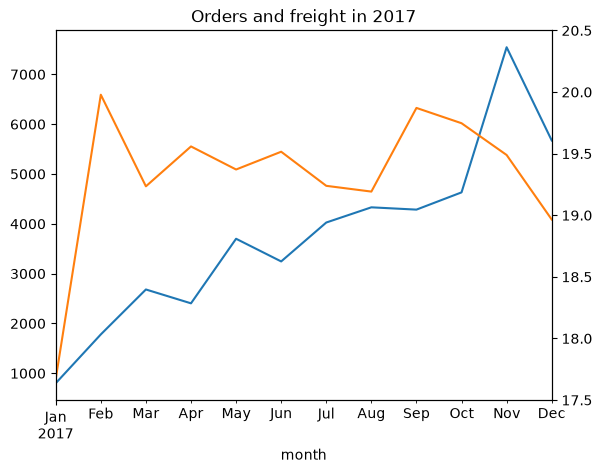

In [19]:
#wrong-1
ax = monthly_2017["orders"].plot(color="tab:blue")

right_axis = ax.twinx()

monthly_2017["freight"].plot(ax=right_axis, color="tab:orange")

right_axis.set_ylim(17.5, 20.5)

ax.set_title("Orders and freight in 2017")

plt.show()


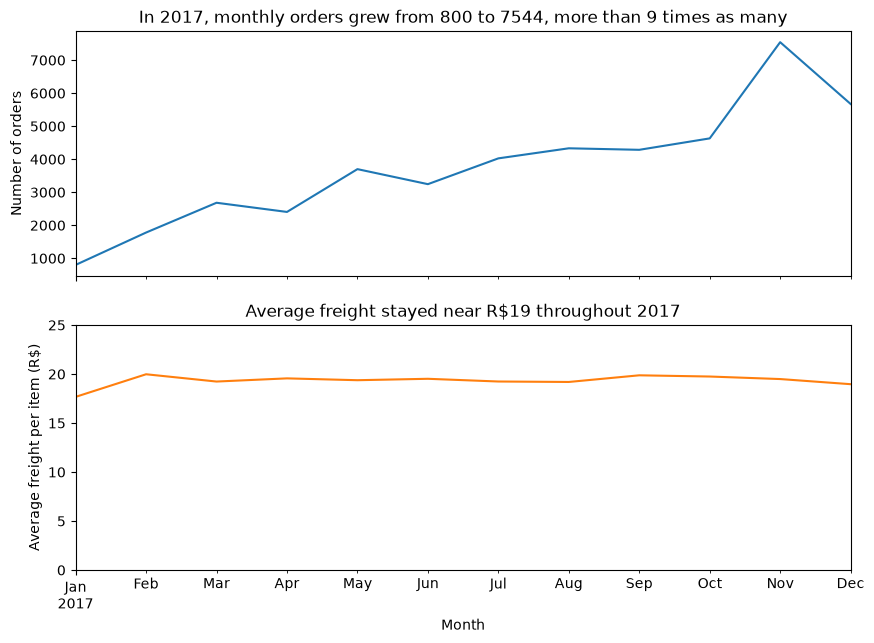

In [20]:
#fix-1
fig, (orders_ax, freight_ax) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True
)

monthly_2017["orders"].plot(ax=orders_ax, color="tab:blue")
orders_ax.set_title("In 2017, monthly orders grew from 800 to 7544, more than 9 times as many")
orders_ax.set_ylabel("Number of orders")

monthly_2017["freight"].plot(ax=freight_ax, color="tab:orange")
freight_ax.set_title("Average freight stayed near R$19 throughout 2017")
freight_ax.set_ylabel("Average freight per item (R$)")
freight_ax.set_xlabel("Month")
freight_ax.set_ylim(0, 25)

fig.savefig(FIGURES / "day-10-fix-1.png", bbox_inches="tight")

plt.show()

This code fixes the misleading chart by creating two separate line charts, one above the other, instead of using two Y-axes in the same chart. The charts share the same X-axis, allowing monthly comparisons while keeping each measurement on its own scale. Clear titles and axis labels explain the order counts and average freight costs. The corrected figure is saved as day-10-fix-1.png.

## Chart 2 — Area for One Number

In [21]:

states = query("""
    SELECT c.customer_state AS state, COUNT(*) AS orders
    FROM clean.orders AS o
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
    GROUP BY c.customer_state
    ORDER BY orders DESC
    LIMIT 5
""")

states


,state,orders
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045


This query retrieves the five states with the highest number of orders. It joins the orders and customers tables to identify each customer's state, groups the records by state, counts the orders, and sorts the results in descending order.

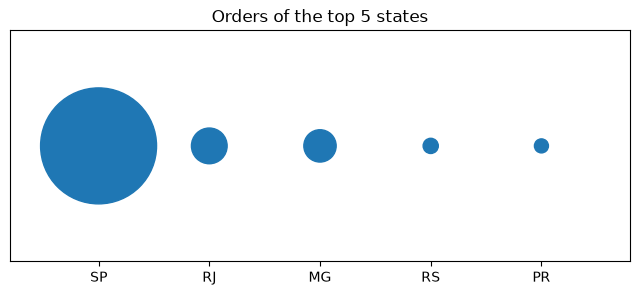

In [22]:
#wrong-2

fig, ax = plt.subplots(figsize=(8, 3))

ax.scatter(states["state"], [1] * 5, s=(states["orders"] / 500) ** 2)

ax.set_xlim(-0.8, 4.8)
ax.set_yticks([])
ax.set_title("Orders of the top 5 states")

plt.show()


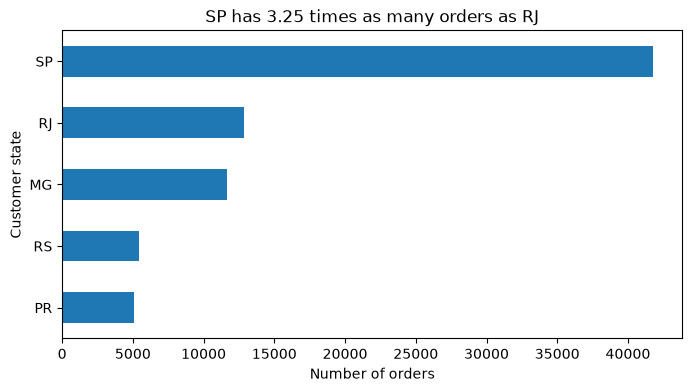

In [23]:
#fix-2

ax = states.sort_values("orders").plot(
    kind="barh",
    x="state",
    y="orders",
    legend=False,
    figsize=(8, 4)
)

ax.set_title("SP has 3.25 times as many orders as RJ")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Customer state")

ax.figure.savefig(FIGURES / "day-10-fix-2.png", bbox_inches="tight")

plt.show()


This code replaces the circle-based chart with a horizontal bar chart to compare the number of orders across the top five states. The data is sorted in ascending order so that the state with the highest number of orders appears at the top. Clear titles and axis labels make the comparison easier to understand. The corrected chart is saved as day-10-fix-2.png.

## Chart 3 — Too Many Colors

In [24]:

top_15 = query("""
    SELECT p.category, SUM(i.price) AS sales
    FROM clean.order_items AS i
    JOIN clean.products AS p ON p.product_id = i.product_id
    GROUP BY p.category
    ORDER BY sales DESC
    LIMIT 15
""").set_index("category")

top_15


,sales
category,
health_beauty,1258681.34
watches_gifts,1205005.68
bed_bath_table,1036988.68
sports_leisure,988048.97
computers_accessories,911954.32
furniture_decor,729762.49
cool_stuff,635290.85
housewares,632248.66
auto,592720.11


This query retrieves the top 15 product categories based on total item sales. It joins the order_items and products tables, groups the results by product category, calculates the total sales using SUM(), and sorts the categories in descending order. Finally, the category column is set as the DataFrame index.

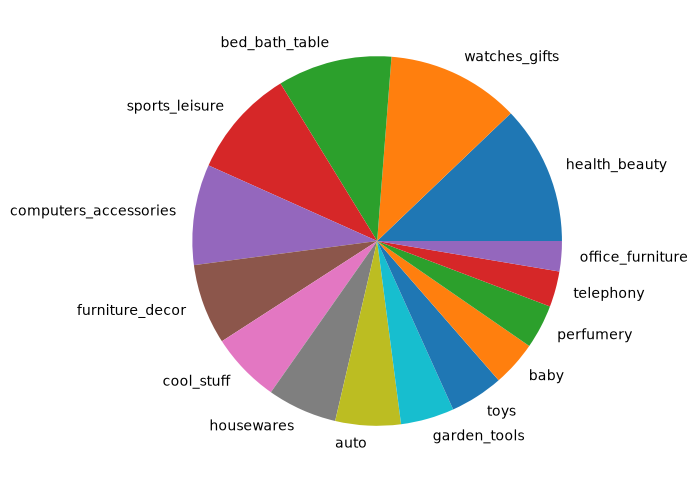

In [25]:
#wrong-3
ax = top_15["sales"].plot(kind="pie", figsize=(6, 6))

ax.set_ylabel("")

plt.show()


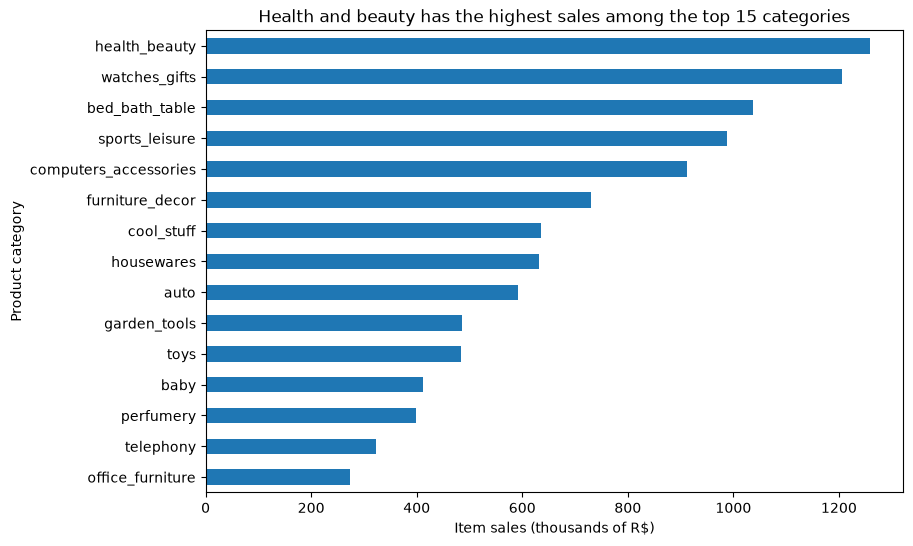

In [26]:
#fix-3

ax = (top_15["sales"] / 1000).sort_values().plot(
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

ax.set_title("Health and beauty has the highest sales among the top 15 categories")
ax.set_xlabel("Item sales (thousands of R$)")
ax.set_ylabel("Product category")

ax.figure.savefig(FIGURES / "day-10-fix-3.png", bbox_inches="tight")

plt.show()


This code replaces the pie chart with a horizontal bar chart to make the sales of the top 15 product categories easier to compare. The categories are sorted in ascending order so that the highest-selling category appears at the top. Clear axis labels and a meaningful title help communicate the main finding. The corrected chart is saved as day-10-fix-3.png.

## Chart 4 — A Month That Is Not There

In [27]:

first_months = query("""
    SELECT date_trunc('month', order_purchase_timestamp) AS month, COUNT(*) AS orders
    FROM clean.orders
    WHERE order_purchase_timestamp < '2017-04-01'
    GROUP BY 1
    ORDER BY 1
""")

first_months


,month,orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682


This query retrieves the monthly number of orders from the beginning of the dataset until March 2017. It groups purchase timestamps by month, counts the orders in each month, and sorts the results chronologically. The query returns only months that have recorded orders.

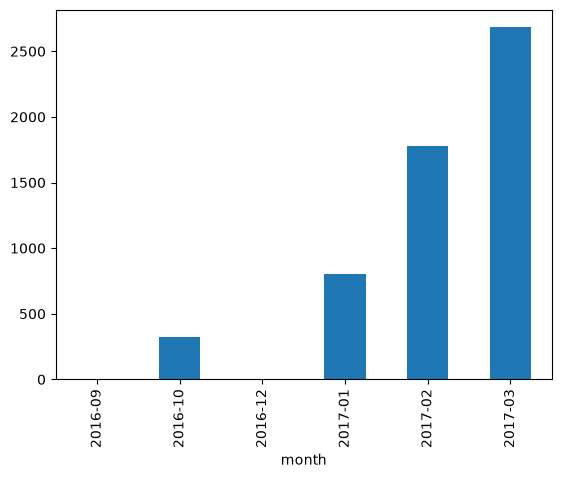

In [28]:
#wrong-4

ax = first_months.plot(
    kind="bar",
    x="month",
    y="orders",
    legend=False
)

ax.set_xticklabels(first_months["month"].dt.strftime("%Y-%m"))

plt.show()


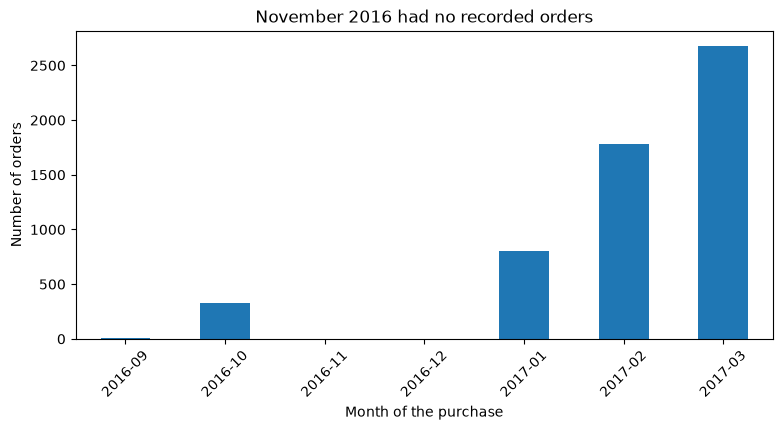

In [29]:
#fix-4

monthly_orders = (
    first_months
    .set_index("month")["orders"]
    .resample("MS")
    .sum()
)

ax = monthly_orders.plot(kind="bar", figsize=(9, 4))

ax.set_title("November 2016 had no recorded orders")
ax.set_xlabel("Month of the purchase")
ax.set_ylabel("Number of orders")

ax.set_xticklabels(monthly_orders.index.strftime("%Y-%m"), rotation=45)

ax.figure.savefig(FIGURES / "day-10-fix-4.png", bbox_inches="tight")

plt.show()


This code fixes the missing month problem by setting the month column as the index and using resample("MS").sum() to create a continuous monthly sequence. Months without recorded orders are included with a value of zero. The corrected bar chart displays all months in chronological order, with clear titles and axis labels. The chart is saved as day-10-fix-4.png.

## Chart 5 — No Message

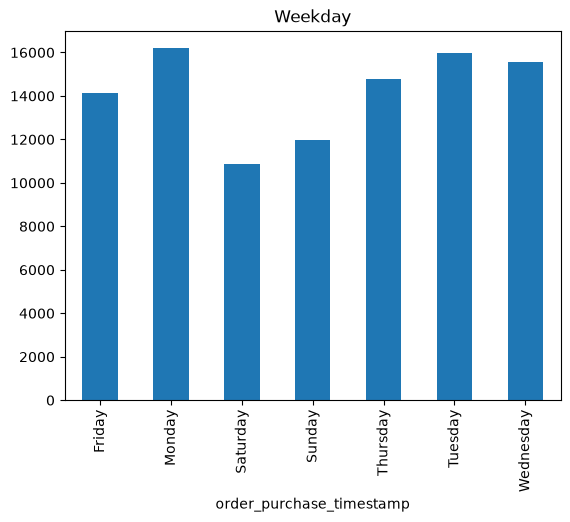

In [30]:
#wrong-5

weekdays = purchases["order_purchase_timestamp"].dt.day_name()

ax = weekdays.value_counts().sort_index().plot(kind="bar")

ax.set_title("Weekday")

plt.show()


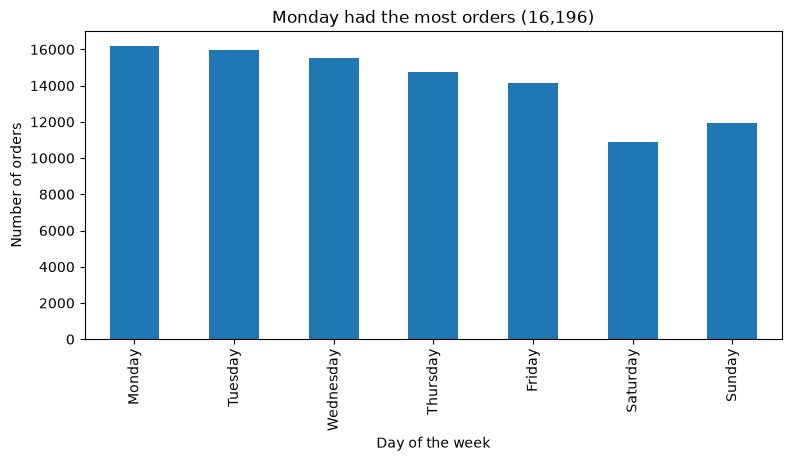

In [31]:
#fix-5

weekdays = purchases["order_purchase_timestamp"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_counts = weekdays.value_counts().reindex(day_order, fill_value=0)

busiest_day = weekday_counts.idxmax()
busiest_count = weekday_counts.max()

ax = weekday_counts.plot(kind="bar", figsize=(9, 4))

ax.set_title(f"{busiest_day} had the most orders ({busiest_count:,})")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Number of orders")

ax.figure.savefig(FIGURES / "day-10-fix-5.png", bbox_inches="tight")

plt.show()


This code fixes the original weekday chart by arranging the days in their correct weekly order using reindex(). It counts the orders for each day, identifies the busiest day and its order count, and uses these results to create a dynamic message title. Clear axis labels are added, and the corrected chart is saved as day-10-fix-5.png.

In [32]:

top_4 = query("""
    SELECT date_trunc('day', o.order_purchase_timestamp) AS day, p.category, COUNT(*) AS items
    FROM clean.order_items AS i
    JOIN clean.orders AS o ON o.order_id = i.order_id
    JOIN clean.products AS p ON p.product_id = i.product_id
    WHERE o.order_purchase_timestamp >= '2017-10-01'
      AND o.order_purchase_timestamp < '2018-01-01'
      AND p.category IN ('bed_bath_table', 'sports_leisure', 'furniture_decor', 'health_beauty')
    GROUP BY 1, 2
    ORDER BY 2, 1
""")

top_4


,day,category,items
0,2017-10-01,bed_bath_table,19
1,2017-10-02,bed_bath_table,17
2,2017-10-03,bed_bath_table,22
3,2017-10-04,bed_bath_table,12
4,2017-10-05,bed_bath_table,17
...,...,...,...
363,2017-12-27,sports_leisure,8
364,2017-12-28,sports_leisure,8
365,2017-12-29,sports_leisure,6
366,2017-12-30,sports_leisure,7


This query retrieves the daily number of items sold for four selected product categories between October and December 2017. It joins the order_items, orders, and products tables to connect each item with its purchase date and category. The results are grouped by day and category, then sorted by category and date.

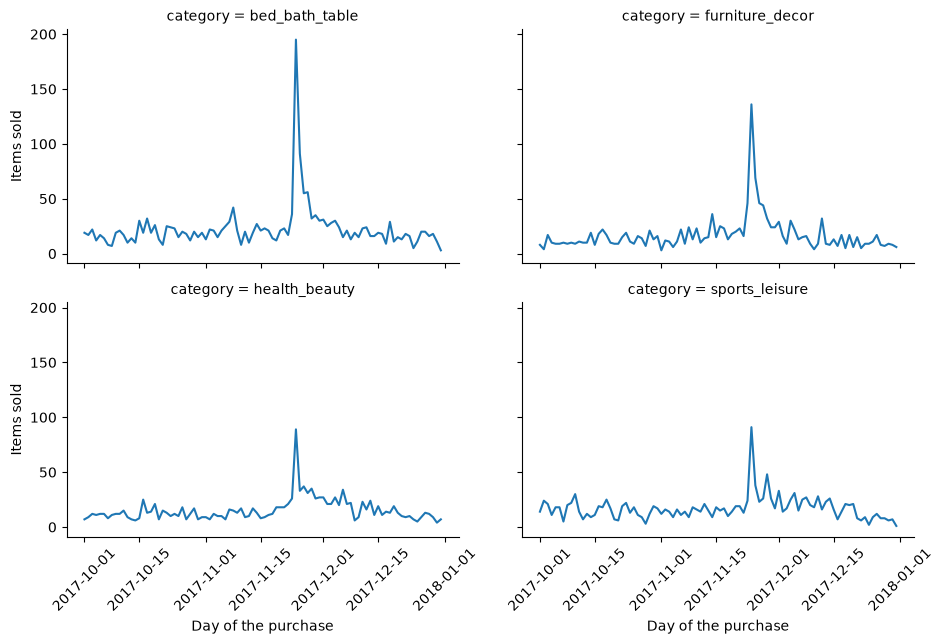

In [33]:

grid = sns.relplot(
    data=top_4,
    x="day",
    y="items",
    col="category",
    col_wrap=2,
    kind="line",
    height=3,
    aspect=1.6
)

grid.set_axis_labels("Day of the purchase", "Items sold")
grid.tick_params(axis="x", rotation=45)

plt.show()


This code uses Seaborn's relplot() function to create four small line charts, one for each product category. The charts display daily items sold from October to December 2017. They share the same axes, making it easier to compare the number of items sold across categories. The axis labels are applied to all charts, and the date labels are rotated to improve readability.

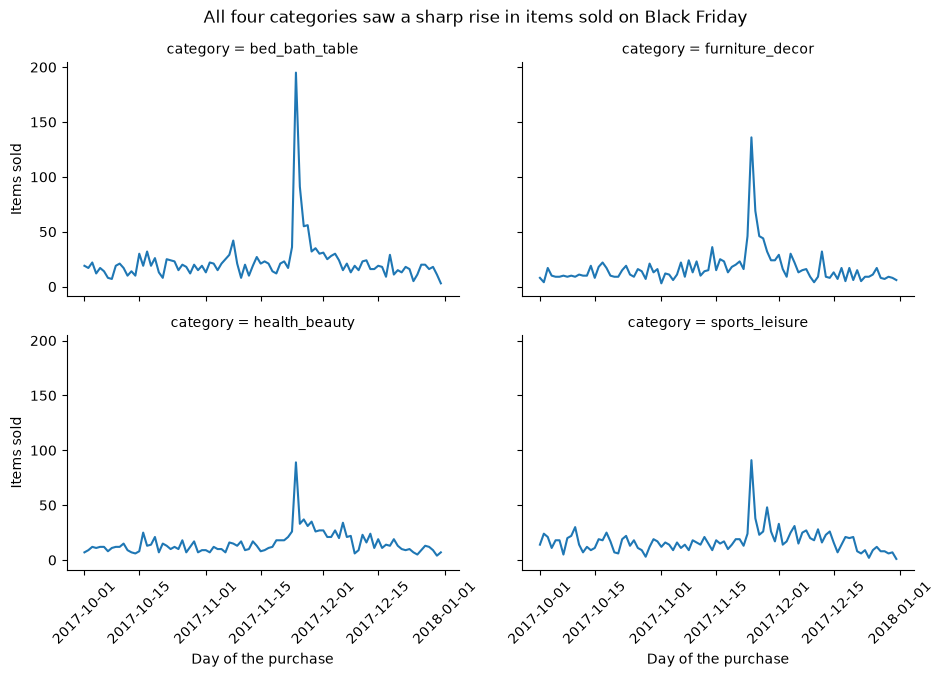

In [34]:

grid = sns.relplot(
    data=top_4,
    x="day",
    y="items",
    col="category",
    col_wrap=2,
    kind="line",
    height=3,
    aspect=1.6
)

grid.set_axis_labels("Day of the purchase", "Items sold")
grid.tick_params(axis="x", rotation=45)

grid.figure.suptitle(
    "All four categories saw a sharp rise in items sold on Black Friday",
    y=1.03
)

grid.savefig(FIGURES / "day-10-categories-black-friday.png")

plt.show()


This code adds a shared message title above the four small charts to highlight the sharp increase in items sold across all categories during Black Friday. The title is positioned slightly above the charts using suptitle(). The complete figure is saved as day-10-categories-black-friday.png in the reports/figures directory.

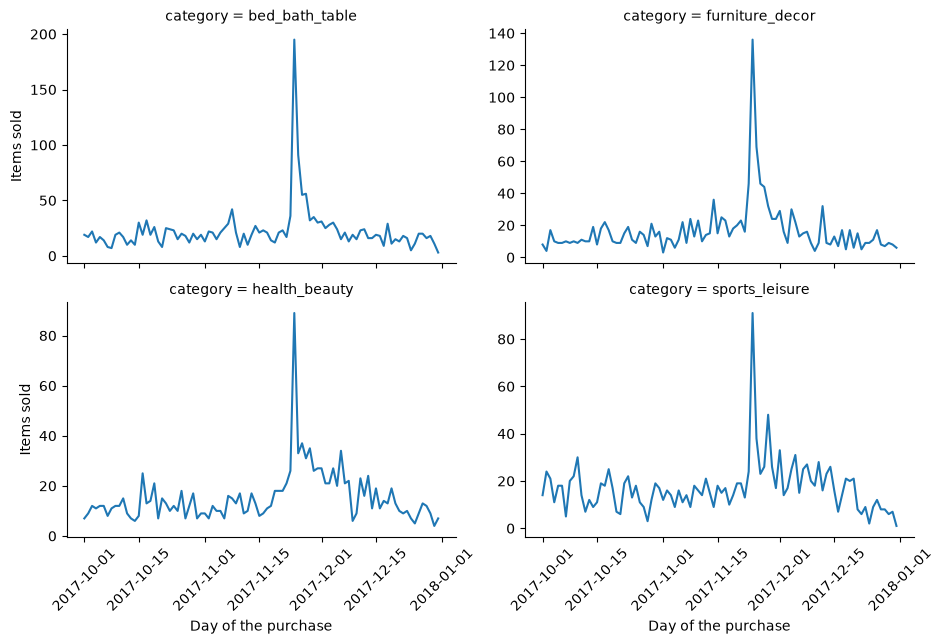

In [35]:
#4.a

grid_independent = sns.relplot(
    data=top_4,
    x="day",
    y="items",
    col="category",
    col_wrap=2,
    kind="line",
    height=3,
    aspect=1.6,
    facet_kws={"sharey": False}
)

grid_independent.set_axis_labels("Day of the purchase", "Items sold")
grid_independent.tick_params(axis="x", rotation=45)

plt.show()


This exercise uses facet_kws={"sharey": False} to give each small chart its own Y-axis scale. This makes it easier to see changes within categories that have different value ranges. However, it reduces direct comparison between the actual number of items sold across categories because each chart uses a different vertical scale.

In [36]:

fig = px.line(
    daily.reset_index(),
    x="day",
    y=["orders", "average_7_days"],
    title="Orders per day, from October to December 2017"
)

fig.show()


This code uses Plotly Express to create an interactive line chart showing daily orders and the 7-day rolling average from October to December 2017. The reset_index() function converts the day index back into a regular column. Users can hover over the lines to view exact values and zoom into specific periods to explore the data in more detail.

## 5.a
The Plotly chart was zoomed into the week of Black Friday to inspect the values for November 24, 2017. The actual number of orders was 1,176, while the 7-day rolling average was 346.4. The interactive chart made it easier to inspect the exact values for a specific date.

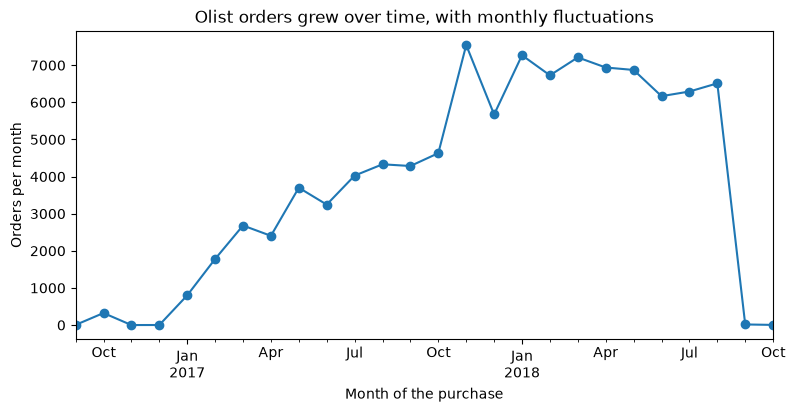

In [37]:

months = query("""
    SELECT date_trunc('month', order_purchase_timestamp) AS month, COUNT(*) AS orders
    FROM clean.orders
    GROUP BY 1
    ORDER BY 1
""").set_index("month")["orders"].resample("MS").sum()

ax = months.plot(marker="o", figsize=(9, 4))
ax.set_xlabel("Month of the purchase")
ax.set_ylabel("Orders per month")
ax.set_title("Olist orders grew over time, with monthly fluctuations")

ax.figure.savefig(
    FIGURES / "day-10-orders-per-month.png",
    bbox_inches="tight"
)
plt.show()


This query calculates the total number of orders for every month in the Olist dataset. The results are grouped by month and sorted chronologically. The resample("MS").sum() operation creates a continuous monthly sequence and fills months without recorded orders with zero. A line chart with circular markers is then used to display the monthly order trend.

In [38]:

ax.set_title("Olist orders grew over time, with monthly fluctuations")

ax.set_xlabel("Month of the purchase")
ax.set_ylabel("Orders per month")

ax.figure.savefig(
    FIGURES / "day-10-orders-per-month.png",
    bbox_inches="tight"
)

plt.show()


This code adds a message title to the monthly orders chart, describing the overall trend in Olist's orders. It also ensures that both axes have clear labels. Finally, the chart is saved as a PNG image in the reports/figures directory for use in the final finding report.
